# Спринт 2 - Проект модуля - нейросеть для автодополнения текстов

## Этап 0 - подготовка
см. [readme.md](readme.md) для установки python и зависимостей

## Этап 1 - загрузка и подготовка данных

1. Загрузить датасет WikiText-2.
2. Провести разведочный анализ: посмотреть примеры текстов, посчитать статистики (число предложений, среднюю длину, распределение длин).
3. Реализовать пословную токенизацию: построить словарь на обучающей выборке с порогом по частоте.
4. Сформировать последовательности фиксированной длины для обучения.
5. Создать `torch.Dataset` и `DataLoader`.

### Загрузка датасета

In [22]:
# загрузка датасета

from datasets import load_dataset

wiki_ds = load_dataset('wikitext', 'wikitext-2-raw-v1')
wiki_ds

Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at d:\AI_tools\huggingface\datasets\wikitext\wikitext-2-raw-v1\0.0.0\b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Tue Oct 13 17:18:06 2026).


DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})

### Cодержимое текстов

In [ ]:
# посмотрим на содержимое - поле [text]

tokens = wiki_ds['train']['text']
print(f'train texts size = {len(tokens)}')

print('content of first 5 texts:')
for i,text in enumerate(tokens[0:5]):
    print(f'{i}: size = {len(text)}, text: [{text}]')

train texts size = 36718
content of first 5 texts:
0: size = 0, text: []
1: size = 30, text: [ = Valkyria Chronicles III = 
]
2: size = 0, text: []
3: size = 706, text: [ Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . 
]
4: size = 524, text: [ The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chr

### Распределение длины текста

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.axes import Axes

def calc_stats_for_ds(texts, ds_title, ax: Axes):
    """
    Подсчет и вывод статистики по длине текста:
    - всего (total) 
    - не пустые (non zero)
    - среднее (average)
    - медиана (median)
    - 5% перцентиль (5% percentile)
    - 95% перцентиль (95% percentile)

    Args
    --
    texts: list 
        список текстов из датасетов
    ds_title: string 
        название датасета
    ax: Axes 
        axes для выпода графика    

    """
    print(f'Stats for dataset = {ds_title}')

    text_len = [len(text) for text in texts]
    print(f'    total = {len(text_len)}')
    print(f'    non zero = {np.count_nonzero(text_len)}')
    print(f'    average = {np.average(text_len):.2f}')
    print(f'    median = {np.median(text_len)}')
    print(f'    5% percentile = {np.percentile(text_len, 5)}')
    print(f'    95% percentile = {np.percentile(text_len, 95)}')

    ax.hist(text_len, bins=20)
    ax.set_xlabel('text length');
    ax.legend([ds_title])
    ax.set_title(f'{ds_title} - text length histogram');
    ax.grid(True)    


Stats for dataset = train
    total = 36718
    non zero = 23767
    average = 296.67
    median = 33.0
    5% percentile = 0.0
    95% percentile = 1135.0
Stats for dataset = validation
    total = 3760
    non zero = 2461
    average = 303.76
    median = 36.0
    5% percentile = 0.0
    95% percentile = 1138.0999999999995
Stats for dataset = test
    total = 4358
    non zero = 2891
    average = 295.00
    median = 35.0
    5% percentile = 0.0
    95% percentile = 1128.2999999999993


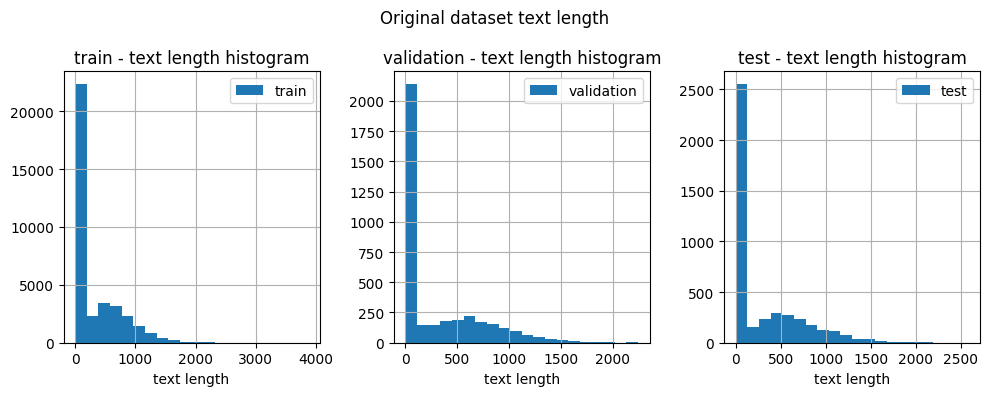

In [5]:
# посчитаем распределение длины текста

fig, axs = plt.subplots(1,3,figsize=(10,4))
for i, ds_name in enumerate(['train', 'validation', 'test']):
    calc_stats_for_ds(wiki_ds[ds_name]['text'], ds_name, axs[i])

plt.suptitle('Original dataset text length')
plt.tight_layout()
plt.show()

Видим, что почти 1/3 датасета содержит строки нулевого размера
Отфильтруем их и посмотрим на те, которые не нулевые

### Распределение длины текста после фильтра пустых строк

In [20]:
def filter_zero_length_text(text_ds):
    """
    Фильтрует тексты нулевого размера.

    Args
    --
        text_ds: dict - словарь с текстами (с ключом `text`)
    
    Return
    --
        list[str]: очищенный список текстов
    
    """
    nonzero_texts = [text for text in text_ds['text'] if len(text) != 0]
    return nonzero_texts


Stats for dataset = train
    total = 23767
    non zero = 23767
    average = 458.32
    median = 401.0
    5% percentile = 19.0
    95% percentile = 1258.0
Stats for dataset = validation
    total = 2461
    non zero = 2461
    average = 464.10
    median = 404.0
    5% percentile = 20.0
    95% percentile = 1250.0
Stats for dataset = test
    total = 2891
    non zero = 2891
    average = 444.70
    median = 375.0
    5% percentile = 18.0
    95% percentile = 1253.5


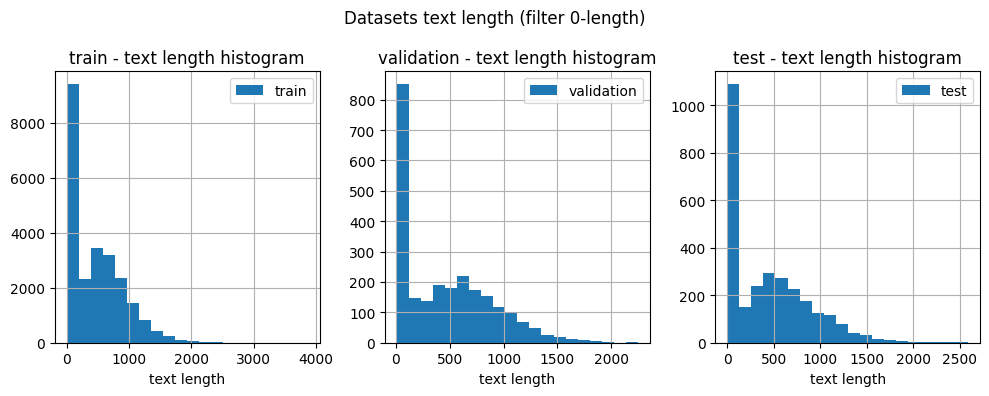

In [7]:
# посчитаем среднюю длину текста, кроме 0-длины

import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1,3,figsize=(10,4))
for i, ds_name in enumerate(['train', 'validation', 'test']):
    nonzero_texts = filter_zero_length_text(wiki_ds[ds_name])
    calc_stats_for_ds(nonzero_texts, ds_name, axs[i])

plt.suptitle('Datasets text length (filter 0-length)')
plt.tight_layout()
plt.show()

Дополнительно рассмотрим короткие тексты до 100 слов

Stats for dataset = train
    total = 8454
    non zero = 8454
    average = 32.84
    median = 28.0
    5% percentile = 16.0
    95% percentile = 72.0
Stats for dataset = validation
    total = 812
    non zero = 812
    average = 32.94
    median = 29.0
    5% percentile = 17.0
    95% percentile = 67.44999999999993
Stats for dataset = test
    total = 1056
    non zero = 1056
    average = 32.61
    median = 29.0
    5% percentile = 14.0
    95% percentile = 69.0


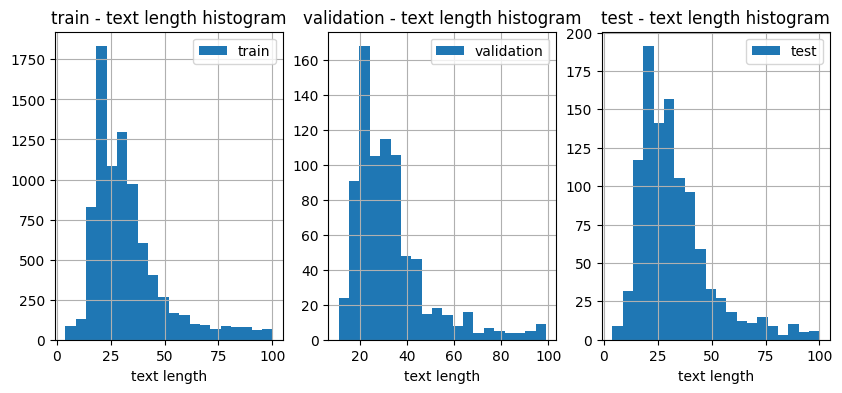

In [8]:

fig, axs = plt.subplots(1,3,figsize=(10,4))
for i, ds_name in enumerate(['train', 'validation', 'test']):
    text_short = [text for text in wiki_ds[ds_name]['text'] if len(text) > 0 and len(text) <= 100]
    calc_stats_for_ds(text_short, ds_name, axs[i])
    

Итого - средняя (медиана) длины текста:
- train = 401.0
- validation = 404.0
- test = 375.0

### Очищенный датасет
- преобразуем в pandas.Dataframe 
- сохраним в csv

In [24]:
import pathlib as path
import pandas as pd

stages = ['train', 'validation', 'test']
data = {'stage': stages, 'texts': []}

# фильтрация пустых строк
for ds_name in stages:
    text_clean = filter_zero_length_text(wiki_ds[ds_name])
    data['texts'].append(text_clean)

wiki_df = pd.DataFrame(data)
wiki_df = wiki_df.explode('texts').reset_index(drop=True)

# save to file
preprocessing_path = path.Path('data/preprocessing')
preprocessing_path.mkdir(parents=True, exist_ok=True)
wiki_df.to_csv(preprocessing_path/'dataset.csv', index=False)

wiki_df

,stage,texts
0,train,= Valkyria Chronicles III = \n
1,train,Senjō no Valkyria 3 : Unrecorded Chronicles (...
2,train,"The game began development in 2010 , carrying..."
3,train,"It met with positive sales in Japan , and was..."
4,train,= = Gameplay = = \n
...,...,...
29114,test,AFI 's 10 Top 10 - # 6 Sports Film \n
29115,test,= = Legacy = = \n
29116,test,"In the decades since its release , The Hustle..."
29117,test,Paul Newman reprised his role as Fast Eddie F...


### Пословная токенизация для словаря на обучающей выборке
- проанализируем частоту появления слов в тексте 
- определим порог частоты для исключения редких слов, так чтобы не сильно сокращать исходный текст 

In [92]:
# функция очистки и подготовки текста

import re
def preprocess_text(text: str) -> str:
    """
    Предобработка текста перед токенизацией.
    - приведение к нижнему регистру
    - удаление спецсимволов
    - удаление дублирующихся пробелов и пробелах в конце или начале

    Return
    --
        text - очищенный текст    
    """

    # приведение к нижнему регистру
    text = text.lower()
    # удаление всех символов, кроме букв, чисел и пробелов
    text = re.sub(r'[^a-zа-яё0-9 ]+', '', text)
    # удаление дублирующихся пробелов и пробелов в начале и в конце
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [90]:
# загрузка из файла

import pandas as pd
import pathlib as path

preprocessing_path = path.Path('data/preprocessing')
wiki_df = pd.read_csv(preprocessing_path/'dataset.csv')
wiki_df

,stage,texts
0,train,= Valkyria Chronicles III = \n
1,train,Senjō no Valkyria 3 : Unrecorded Chronicles (...
2,train,"The game began development in 2010 , carrying..."
3,train,"It met with positive sales in Japan , and was..."
4,train,= = Gameplay = = \n
...,...,...
29114,test,AFI 's 10 Top 10 - # 6 Sports Film \n
29115,test,= = Legacy = = \n
29116,test,"In the decades since its release , The Hustle..."
29117,test,Paul Newman reprised his role as Fast Eddie F...


all_words size = 1,748,743
counter total words = 1,748,743, unique words count = 65,357
top 10 words:
    the  : 130,769   
    of   : 57,032    
    and  : 50,735    
    in   : 45,016    
    to   : 39,522    
    a    : 36,454    
    was  : 21,008    
    on   : 15,143    
    as   : 15,062    
    s    : 14,493    


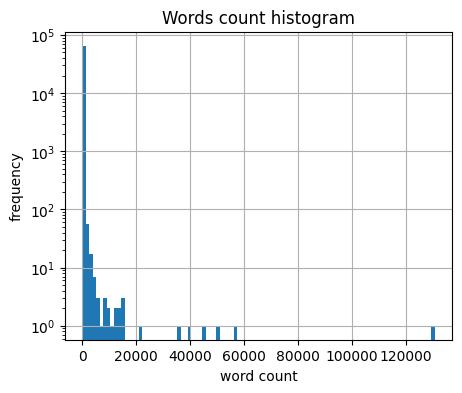

In [93]:
# счетчик слов для анализа частотности
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# формируем словарь из слов обучающей выборки
train_texts = wiki_df[wiki_df['stage'] == 'train']['texts']

# составим словарь всех слов на предобработанных текстах, исключая спецсимволы и пунктуацию
all_words = [word for text in train_texts for word in preprocess_text(text).split()]

print(f'all_words size = {len(all_words):,}')

counter = Counter(all_words)
print(f'counter total words = {counter.total():,}, unique words count = {len(counter):,}')
print(f'top 10 words:')
for w,c in counter.most_common(10): 
    print(f'    {w:5}: {c:<10,}')

# построим гистограмму частоты слов
word_freq = np.array(list(counter.values()))
plt.figure(figsize=(5,4))
plt.hist(word_freq, bins=100, log=True)
plt.xlabel('word count');plt.ylabel('frequency')
plt.title('Words count histogram')
plt.grid(True)

In [28]:
# определим порог частоты для фильтрации редких слов

freqs = np.array(list(counter.values()))
total = freqs.sum()

# посмотрим какой объем занимают наименее частотные слова
print(f"{'min_freq':>8} | {'vocab':>7} | {'% vocab':>7} | {'% tokens kept':>12} | {'% tokens removed':>8}")
for mf in [1, 2, 3, 5, 10, 20]:
    kept = freqs[freqs >= mf]
    print(f"{mf:>8} | {len(kept):>7,} | {len(kept)/len(freqs):>7.1%} | {kept.sum()/total:>13.2%} | {(total-kept.sum())/total:>8.2%}")

min_freq |   vocab | % vocab | % tokens kept | % tokens removed
       1 |  65,357 |  100.0% |       100.00% |    0.00%
       2 |  38,915 |   59.5% |        98.49% |    1.51%
       3 |  29,369 |   44.9% |        97.40% |    2.60%
       5 |  20,871 |   31.9% |        95.75% |    4.25%
      10 |  13,130 |   20.1% |        92.84% |    7.16%
      20 |   8,184 |   12.5% |        89.02% |   10.98%


Получается, что исключая слова с частотой менее 3-х (min_freq == 3):
- мы существенно сократим размер словаря - до 44.9%, что составит 29.370 токенов (и уберем 35.991 редких слов), 
- при этом заменим (исключим) всего 2,57% токенов  (заменим на специальный токен `<UNK>`)

То есть минимально повлияем на анализ смысла текстов, при существенном сокращении объема неинформативных данных, что должно упростить модель и позволить ей более эффективно учиться

### Фильтрация редких слов из словаря
- уберем редкие слова из словаря - те, чья частота менее 3-х раз во всем корпусе
- заменим в датасет исключаемые слова на специальный токен `<UNK>` для сохранения консистентности текстов

In [ ]:
# отбор редких слов

import pathlib as path
import pandas as pd

rare_words = []
freq_threshold = 3
vocab = []

# отбор слов в словарь
for w,c in counter.items():
    if c < freq_threshold:
        rare_words.append(w)
    else:
        vocab.append(w)
        
print(f'rare_words size = {len(rare_words)}')
print(f'vocab size = {len(vocab)}')

# сохраним в файл
preprocessing_path = path.Path('data/preprocessing')

pd.DataFrame(rare_words, columns=['rare_word']) \
    .to_csv(preprocessing_path/'rare_words.csv', index=False)

# добавляем в словарь специальные слова для дальнейшей консистентности с датасетом
UNK_WORD = '<UNK>'
PAD_WORD = '<PAD>'
vocab.append(UNK_WORD)
vocab.append(PAD_WORD)

pd.DataFrame(vocab, columns=['word']) \
    .to_csv(preprocessing_path/'vocab.csv', index=False)

rare_words size = 35988
vocab size = 29369


In [ ]:
# заменим все редкие слова на специальный токен <UNK> во всех текстах датасета
# работает ~ 11 мин

import tqdm
import re

# токен замены
UNK_WORD = '<UNK>'

# компилируем регулярное выражение: только целые слова (по границам слов)
rare_words_pattern = re.compile(
    r'\b(?:' + '|'.join(re.escape(w) for w in rare_words) + r')\b'
)

def replace_rare_words(text: str) -> str:
    """
    Заменяет все редкие слова в тексте на токен <UNK>.

    Return
    --
        text - текст с замененными редкими словами
    """
    return rare_words_pattern.sub(UNK_WORD, text)

clean_df = wiki_df.copy()
BATCH = 500
n = clean_df.shape[0]

tokens = list(clean_df['texts'])

for start in tqdm.tqdm(range(0, clean_df.shape[0], 500), desc='texts'):
    end = min(start + BATCH, n) 
    idx = clean_df.index[start:end]

    # очищаем текст + применяем замену ко всем текстам
    tokens[start:end] = [replace_rare_words(preprocess_text(t)) for t in tokens[start:end]]

clean_df['texts'] = tokens 
clean_df['texts'] = clean_df['texts'].dropna()

# сохраним обновленный датасет
preprocessing_path = path.Path('data/preprocessing')
clean_df.to_csv(preprocessing_path / 'dataset_clean.csv', index=False)

clean_df

Проверка, что замена выполнена

In [ ]:
# set для быстрой проверки принадлежности слова к редким
rare_words_set = set(rare_words)

# проверим, что редких слов больше не осталось
train_texts = clean_df[clean_df['stage'] == 'train']['texts']

# количество текстов, все еще содержащих редкие слова (без учета токена <UNK>)
contains_rare = train_texts.apply(
    lambda text: any(word in rare_words_set for word in text.split())
)
print(f'texts with rare words left = {contains_rare.sum():,}')

unk_count = train_texts.str.count(r"<UNK>").sum()
print(f'total <UNK> tokens in train = {unk_count:,}')

# ожидается доля <UNK> токенов ~ 2,6%: 
total_train_tokens = train_texts.str.split().apply(len).sum()
print(f'train tokens = {total_train_tokens:,}')
print(f'<UNK> share = {unk_count / total_train_tokens:.2%}')

texts with rare words left = 0
total <UNK> tokens in train = 45,534
train tokens = 1,748,743
<UNK> share = 2.60%


### Токенизатор для работы со словарем
- обернем подготовленный словарь (vocab) в токенизатор для удобства работы

In [ ]:
import numpy as np
import pandas as pd

class WikiTextWordTokenizer():
    """
    Токенизатор для словаря  - превращает отсортированные уникальные слова в их индексы.
    Специальное слово `<UNK>` применяется для замены в случае отсутсвия слова в словаре (проблема-OOV).
    Специальное слово `<PAD>` используется для пэддинга коротких текстов при передаче в модель
    Для спецслов зарезервированы индексы:
    - <PAD> - 0 - для совместимости с датасетом
    - <UNK> - 1 - для удобства расположим тоже вначале

    """
    def __init__(self, word_vocab: list):
        print(f'WikiTextWordTokenizer __init__() word_vocab len = {len(word_vocab)}')

        self.UNK_WORD = '<UNK>'
        self.PAD_WORD = '<PAD>'
        self.PAD_TOKEN = 0 # this is `0` in other torch dataset operations
        self.UNK_TOKEN = 1 # 1 for simplicity

        # preserve order for unique words + special words to start of index
        unique_words = sorted(set(word_vocab) - {self.PAD_WORD, self.UNK_WORD})
        self.words = np.array([self.PAD_WORD, self.UNK_WORD] + unique_words)
        
        # map to tokens (which are indexes of words)
        self.word_to_idx = {w:idx for idx,w in enumerate(self.words)}
        
        print(f'words unique_words len = {len(unique_words)}, total len with specials = {len(self.words)}')
        print(f'word_to_idx total len = {len(self.word_to_idx)}')
        
        assert self.word_to_idx[self.PAD_WORD] == self.PAD_TOKEN
        assert self.word_to_idx[self.UNK_WORD] == self.UNK_TOKEN
                
    def tokenize(self, words: list):
        # use map from pandas instead of for loop + handle unknown word (OOV-problem)
        return pd.Series(words).map(self.word_to_idx).fillna(self.UNK_TOKEN).values.astype('int32')

    def conver_to_words(self, tokens: list):
        return self.words[tokens]

#### test

test_vocab = ['a', 'b', 'c']
print(f'test_vocab: {test_vocab}')
tknz = WikiTextWordTokenizer(test_vocab)

test_words = ['a', 'c', 'a', 'X']
print(f'tokenize words = {test_words} to tokens => {tknz.tokenize(test_words)}')

test_tokens = [2, 4, 2, 1, 0]
print(f'convert tokens = {test_tokens} to words => {tknz.conver_to_words(test_tokens)}')
######

test_vocab: ['a', 'b', 'c']
WikiTextWordTokenizer __init__() word_vocab len = 3
words unique_words len = 3, total len with specials = 5
word_to_idx total len = 5
tokenize words = ['a', 'c', 'a', 'X'] to tokens => [2 4 2 1]
convert tokens = [2, 4, 2, 1, 0] to words => ['a' 'c' 'a' '<UNK>' '<PAD>']


### Датасет для модели torch.Dataset
- сформируем обучающие последовательности в виде строк фиксированной длины до 32 символов
- подготовим torch.Dataset

In [120]:
def split_text_chunks(text, seq_len, overlap):
    """
    Разделение текста `text` на цепочки по `seq_len` слов с перекрытием скользящим окном размером `overlap` слов (для перекрестного контекста между цепочками)    
    """

    chunks = []
    #print(f'begin text = {text}, seq_len = {seq_len}, overlap = {overlap}')
    
    # проверка, что параметры корректны
    if overlap >= seq_len or overlap < 1 or seq_len < 3:
        raise ValueError(f'overlap should be less then seq_len - got seq_len = {seq_len}, overlap = {overlap}')

    # первая цепочка - захватываем все что есть до границы seq_len
    start = 0
    end = start + seq_len
    chunk = text[start:end]
    chunks.append(chunk)
    
    # если длина позволяет, разбиваем на цепочки по seq_len с перекрытием размером overlap
    if len(text) > seq_len:
        # количество интервалов зависит от длины и перекрытия
        window_count = len(text) // (seq_len-overlap)
        
        #print(f'first added - chunks = {chunks}, window_count = {window_count}')

        for i in range(window_count):
            start = (i+1) * seq_len - (i+1) * overlap
            end = start + seq_len
            chunk = text[start:end]
            chunks.append(chunk)

            #print(f'i - {i}, chunks = {chunks}, start = {start}, end = {end}')

            if end >= len(text):
                break
       
    return chunks

#### test
# a = [0,1,2,3,4,5,6,7,8,9,10,11,12]
# print(split_text_chunks(a, 4, 1))

# a = [0,1,2,3,4,5,6]
# print(split_text_chunks(a, 4, 1))

a = [0,1,2,3]
print(split_text_chunks(a, 3, 2))
######

[[0, 1, 2], [1, 2, 3]]


In [30]:
a = [0,1,2]
b = [3,4,5]
a.extend(b)
a

[0, 1, 2, 3, 4, 5]

In [118]:
from typing import Dict
import torch
from tqdm import tqdm
import pathlib as path
from torch.utils.data import Dataset

class WikiTextTorchDataset(Dataset):
    """
    Датасет для модели нейросети.
    Формирует пары (X,y), где:
    - X - последовательности фиксированной длины (`seq_len-1`), `seq_len` по-умолчанию равна 32 токена, без последнего токена (который надо будет предсказать)
    - y - последний токен последовательности - для сравнения с предсказанием
    
    Цепочки из текста формируются с перекрытием размером `overlap`.
    """

    def __init__(self, texts: list, tokenizer: WikiTextWordTokenizer, seq_len=32, overlap=16):
        """
        На вход подаются все тексты имеющегося корпуса.
        Каждый текст нарезается на цепочки слов по `seq_len` слов, при этом:
        - короткие тексты (длиной менее `seq_len`) будут дополнены токенами `<PAD>` с помощью `collate_fn()` в DataLoader
        - длинные тексты будут разбиваться скользящим окном на цепочки длиной `seq_len` слов с перекрытием размером `overlap` слов (для перекрестного контекста между цепочками)

        В `X` пойдут все слова (токены) размером от (0, seq_len-1).

        В `y` уйдет последнее слово (на позиции seq_len), котороне надо будет предсказать.
        """
        
        print(f'WikiTextTorchDataset __init()__: texts size = {len(texts)}, seq_len = {seq_len}, overlap = {overlap}')

        self.seq_len = seq_len
        self.overlap = overlap

        self.X = []
        self.y = []
        
        for text in tqdm(texts):
            words = text.split()
            # если текст всего из 2-х слов, то разбить его на X и y не получится
            if len(words) > 2:
                text_tokens = tokenizer.tokenize(words)

                chunks = split_text_chunks(text_tokens, seq_len, overlap)
                
                self.X.extend([chunk[:-1] for chunk in chunks])
                self.y.extend([chunk[-1] for chunk in chunks])

        print(f'self.X len = {len(self.X)}')
        print(f'self.y len = {len(self.y)}')

    def save(self, store_path: path.Path):
        """
        Сохраняет подготовленные последовательности (X, y) в файл,
        чтобы при следующем запуске не токенизировать тексты заново.
        """
        torch.save(
            {
                'seq_len': self.seq_len,
                'overlap': self.overlap,
                'X': self.X,
                'y': self.y,
            },
            store_path,
        )
        print(f'dataset saved to: {store_path}')

    @classmethod
    def load(cls, store_path: path.Path, tokenizer: WikiTextWordTokenizer):
        """
        Загружает сформированный (токенизированный) датасет из файла
        """
        
        if not store_path.exists():
            raise RuntimeError(f'file not exists: {store_path}')

        data = torch.load(store_path, weights_only=False)
        
        ds = cls.__new__(cls)  # пропускаем длинный __init__
        ds.seq_len = data['seq_len']
        ds.overlap = data['overlap']
        ds.X = data['X']
        ds.y = data['y']

        print(f'dataset loaded from file: {store_path} (X len = {len(ds.X)}, y len = {len(ds.y)})')
        return ds

    def __len__(self) -> int:
        return len(self.X)

    def __getitem__(self, index) -> Dict[str, torch.Tensor]:
        """
        Return `(X, y)` tuple of tensors
        """
        return {
            'text': torch.tensor(self.X[index], dtype=torch.int32), 
            'target': torch.tensor(self.y[index], dtype=torch.int32)
        }

In [51]:
# загрузка подготовленного и очищенного датасета

import pathlib as path
import pandas as pd

# сохраним обновленный датасет
preprocessing_path = path.Path('data/preprocessing')
wikitext_df = pd.read_csv(preprocessing_path / 'dataset_clean.csv')
wikitext_df

,stage,texts
0,train,valkyria chronicles iii
1,train,senj no valkyria 3 unrecorded chronicles japan...
2,train,the game began development in 2010 carrying ov...
3,train,it met with positive sales in japan and was pr...
4,train,gameplay
...,...,...
29114,test,<UNK> s 10 top 10 6 sports film
29115,test,legacy
29116,test,in the decades since its release the hustler h...
29117,test,paul newman reprised his role as fast eddie fe...


In [95]:
# загрузка словаря

vocab_df = pd.read_csv(preprocessing_path/'vocab.csv')
vocab_df

,word
0,valkyria
1,chronicles
2,iii
3,senj
4,no
...,...
29366,intergrades
29367,reedbeds
29368,gallinae
29369,<UNK>


In [ ]:
# достаем обучающий набор текстов
train_texts = wikitext_df[wikitext_df['stage'] == 'train']['texts'].dropna().astype(str).values

# параметры последовательностей текстов для обучения
seq_len = 32
seq_overlap = 16

# токенизатор слов
tokenizer = WikiTextWordTokenizer(vocab_df['word'].tolist())

# датасет для обучения
# токенизация текста занимает около 5 минут
train_dataset = WikiTextTorchDataset(texts=train_texts, tokenizer=tokenizer, seq_len=seq_len, overlap=seq_overlap)

WikiTextWordTokenizer __init__() word_vocab len = 29369
words unique_words len = 29369, total len with specials = 29371
word_to_idx total len = 29371
WikiTextTorchDataset __init()__: texts size = 23764, seq_len = 32, overlap = 16


100%|██████████| 23764/23764 [04:53<00:00, 80.90it/s] 

self.X len = 103471
self.y len = 103471


In [ ]:
# save tokenized dataset to file 
import pathlib as path
store_path = path.Path('data/preprocessing')/'dataset_train.pt'
train_dataset.save(store_path)

dataset saved to: data\preprocessing\dataset_train.pt


#### Загрузка подготовленного токенизированного датасета
- с этого места можно загрузить все подготовленные данные и продолжить с DataLoader

In [ ]:
# load tokenized dataset from file 
import pandas as pd
import pathlib as path

preprocessing_path = path.Path('data/preprocessing')

# загрузка словаря
vocab_df = pd.read_csv(preprocessing_path/'vocab.csv')

# токенизатор слов
tokenizer = WikiTextWordTokenizer(vocab_df['word'].tolist())

# датасет
store_path = preprocessing_path/'dataset_train.pt'
train_dataset = WikiTextTorchDataset.load(store_path, tokenizer)

WikiTextWordTokenizer __init__() word_vocab len = 29371
words unique_words len = 29369, total len with specials = 29371
word_to_idx total len = 29371
dataset loaded from file: data\preprocessing\dataset_train.pt (X len = 103471, y len = 103471)


### Загрузчик текстов torch.Dataloader
- подготовим загрузчик данных для пакетной обработки моделью

In [14]:
import torch
from torch.nn.utils.rnn import pad_sequence

def collate_fn(texts: list):
    """
    Дополнение коротких текстов (padding) до максимальной цепочки в батче
    """
    
    x_list = [item['text'] for item in texts]
    y_list = [item['target'] for item in texts]
    len_list =[len(text) for text in x_list]

    # пэддинг коротких текстов
    padded_text = pad_sequence(x_list, batch_first=True, padding_value=0)
    
    return {
        'input_tokens': padded_text,
        'input_lengths': torch.tensor(len_list),
        'targets': torch.tensor(y_list),
    }

In [ ]:
# подготовка загрузчика DataLoader
from torch.utils.data import DataLoader

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, collate_fn=collate_fn, shuffle=True) 
print(f'loader batches = {len(train_loader)}')

# проверка вызова батча
sample_batch = next(iter(train_loader))
print(f'sample_batch = {sample_batch}')

loader batches = 1617
sample_batch = {'input_tokens': tensor([[19271,  1331,   707,  ..., 19607, 13691, 10360],
        [ 2298, 12627,  2119,  ...,  2443, 13691, 13842],
        [17329,  6272, 13691,  ..., 15357, 27271, 26818],
        ...,
        [17935, 23211,     0,  ...,     0,     0,     0],
        [ 2438, 13911,  4802,  ..., 27671,     0,     0],
        [11440, 26680, 29202,  ..., 12204, 26549, 14463]], dtype=torch.int32), 'input_lengths': tensor([31, 31, 31, 31, 31, 31, 31, 31, 19, 24, 19, 26, 31, 30, 31, 28, 31, 31,
        31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 21, 31, 31, 31, 31, 31, 31, 31,
        31, 31, 31, 31, 31, 31, 31, 31,  5, 31, 31, 31, 31, 21, 31,  5, 31, 31,
        31, 31, 31, 31, 31, 31, 31,  2, 29, 31]), 'targets': tensor([26296, 26552,  2298,  1331,  2140, 26552, 18855, 14471,  9093,   726,
            1,     1, 14076, 21260, 21761, 13462,  8415, 15935, 13214,  8928,
         2298, 28350, 17346,  3085, 26549, 25550, 26552, 21843,     1,  4802,
        2682

## Этап 2. Реализация и обучение LSTM

1. Реализовать класс модели: Embedding-слой + LSTM-слой + линейный слой.
2. Написать цикл обучения с выводом train loss, val loss и val perplexity.
3. Обучить модель. Примерные параметры для старта: embedding_dim=128, hidden_dim=256, num_layers=2, seq_len=32, batch_size=64, lr=0.001.
4. Применить gradient clipping для стабилизации обучения.
5. Построиь графики обучения.

### RNN модель (универсальная)

In [266]:
import torch.nn as nn
import pathlib as path

class NNWikiTextComplete(nn.Module):
    """
    Модель нейросети RNN с архитектурой LSTM/GRU для предсказания (дополнения) следующего слова.
    Реализует задачу многоклассовой классификации на выходе из нейросети на множестве слов (классов) из словаря
    """

    def __init__(self, vocab_size: int, emded_dim: int = 128, hidden_dim: int = 256, n_layers: int = 2, dropout = 0, model_type = 'lstm'):
        print(f'NNWikiTextComplete: vocab_size = {vocab_size}, emded_dim = {emded_dim}, hidden_dim = {hidden_dim}, n_layers = {n_layers}, dropout = {dropout}, model_type = {model_type}')

        super().__init__()

        # hyper params
        self.vocab_size = vocab_size
        self.emded_dim = emded_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.dropout = dropout
        self.model_type = model_type

        # create nn layers
        self.embed = nn.Embedding(vocab_size, emded_dim, padding_idx=0)

        cls = {"lstm": nn.LSTM, "gru": nn.GRU}[model_type]
        self.model = cls(input_size=emded_dim, hidden_size=hidden_dim, num_layers=n_layers, batch_first=True, dropout=dropout)
        
        self.fc = nn.Linear(in_features=hidden_dim, out_features=vocab_size)

        # init params
        self._init_weights()

    def _init_weights(self):
        """
        Init model params - Xavier approach (as LSTM and GRU use `tanh` activation)
        """
        nn.init.xavier_uniform_(self.embed.weight) # embeddings
        for name, param in self.model.named_parameters(): # 
            if 'weight' in name:
                nn.init.xavier_uniform_(param)
            elif 'bias' in name:
                nn.init.zeros_(param)
        nn.init.xavier_uniform_(self.fc.weight) # linear
        nn.init.zeros_(self.fc.bias)

    def save_model(self, path: path.Path):
        """
        Сохраняет веса модели и гиперпараметры в файл.
        """
        checkpoint = {
            'state_dict': self.state_dict(),
            'hyperparams': {
                'vocab_size': self.vocab_size,
                'emded_dim': self.emded_dim,
                'hidden_dim': self.hidden_dim,
                'n_layers': self.n_layers,
                'dropout': self.dropout,
                'model_type': self.model_type
            }
        }
        torch.save(checkpoint, path)
        print(f"Model saved to {path}")

    @classmethod
    def load_model(cls, path: path.Path):
        """
        Загружает модель из файла. 
        Сначала восстанавливает архитектуру по гиперпараметрам, затем загружает веса.
        """
        checkpoint = torch.load(path)
        hyperparams = checkpoint['hyperparams']
        
        # Создаем экземпляр класса с сохраненными гиперпараметрами
        model = cls(**hyperparams)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval() # Переводим в режим оценки
        print(f"Model loaded from {path}")
        return model

    def forward(self, input_texts, input_lengths):
        # input shape = (batch, seq_len)
        #print(f'forward() input_texts = {input_texts.shape}, input_lengths = {input_lengths.shape}')

        try:
            emdeb_out = self.embed(input_texts)  # emdeb_out shape = (batch, seq_len, embed_dim)
        except Exception as e:
            print(f'forward() embed exception = {e}')
            print(f"""  input_texts shape = {input_texts.shape},
                        input_texts = {input_texts},
                        input_lengths = {input_lengths}""")
        
        #print(f'    emdeb_out = {emdeb_out.shape}')

        input_padded = nn.utils.rnn.pack_padded_sequence(emdeb_out, lengths=input_lengths, batch_first=True, enforce_sorted=False)

        if self.model_type == 'lstm':
            _, (last_hidden, _) = self.model(input_padded) # last_hidden shape = (layers, batch, hidden_dim)
            
        elif self.model_type == 'gru':
            _, last_hidden = self.model(input_padded) # last_hidden shape = (layers, batch, hidden_dim)
            
        #print(f'    last_hidden = {last_hidden.shape}')

        # take last layer
        out = last_hidden[-1] 

        logits = self.fc(out) # logits shape = (batch, vocab_size)
        #print(f'    logits = {logits.shape}')

        return logits

### Обучение LSTM-модели

In [ ]:
# загрузка данных

import pandas as pd
import pathlib as path

preprocessing_path = path.Path('data/preprocessing')

# загрузка словаря
vocab_df = pd.read_csv(preprocessing_path/'vocab.csv')

# токенизатор слов
tokenizer = WikiTextWordTokenizer(vocab_df['word'].tolist())

# train датасет - заранее токенизирован и сохранен
store_path = preprocessing_path/'dataset_train.pt'
train_dataset = WikiTextTorchDataset.load(store_path, tokenizer)

# val датасет - токенизация налету, т.к. размер меньше
wiki_ds = pd.read_csv(preprocessing_path / 'dataset_clean.csv')
val_texts = wiki_ds[wiki_ds['stage'] == 'validation']['texts'].tolist()
val_dataset = WikiTextTorchDataset(val_texts, tokenizer)

WikiTextWordTokenizer __init__() word_vocab len = 29371
words unique_words len = 29369, total len with specials = 29371
word_to_idx total len = 29371
dataset loaded from file: data\preprocessing\dataset_train.pt (X len = 103471, y len = 103471)
WikiTextTorchDataset __init()__: texts size = 2461, seq_len = 32, overlap = 16


100%|██████████| 2461/2461 [00:31<00:00, 78.79it/s]

self.X len = 10851
self.y len = 10851


#### Логика обучения
- выносим отдельно для переиспользования

In [246]:
def train_model(model, loader, optim, criterion, max_iter = -1):
    """
    Выполнение цикла обучения модели (одна эпоха)

    Returns
    --
        avg_loss - средняя ошибка по всем итерациям
    """

    iteration = 0
    total_loss = 0
    
    model.train()
    for texts in tqdm(loader, desc=f'train epoch - batch size = {batch_size}'):
        iteration += 1
        
        inputs = texts['input_tokens'].to(device)
        lengths = texts['input_lengths'].to(device)
        targets = texts['targets'].to(device, dtype=torch.long)

        optim.zero_grad(set_to_none=True)

        # model predict        
        logits = model(inputs, lengths)
        
        # calc train loss
        loss = criterion(logits, targets)
        total_loss += loss.item()

        # calc grads
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)        

        # update params
        optim.step()

        if iteration % 500 == 0:
            print(f'epoch:{epoch}-iter:{iteration} - loss = {loss}')

        if iteration == max_iter:
            break
    
    return total_loss/iteration

#### Логика валидации
- выносим отдельно для переиспользования

In [247]:
# metrics
def perplexity_metric(loss):
    """
    Метрика perplexity (PPL): 
    - PPL_item = exp(CrossEntropyLoss)
    - PPL_total = 
    """
    return np.exp(loss)

# evaluation loop
def evaluate_model(model, loader, criterion, max_iter = -1):
    """
    Расчет ошибки и метрики на валидации 

    Returns
    --
        (total_loss, ppl_metric)
    """
    avg_loss = 0
    iteration = 0

    model.eval()
    for texts in loader:
        iteration += 1

        inputs = texts['input_tokens'].to(device)
        lengths = texts['input_lengths'].to(device)
        targets = texts['targets'].to(device, dtype=torch.long)

        with torch.no_grad():
            logits = model(inputs, lengths)
            loss = criterion(logits, targets)
            avg_loss += loss.item()

        if iteration == max_iter:
            break

    avg_loss = avg_loss / iteration
    ppl_metric = perplexity_metric(avg_loss)

    return avg_loss, ppl_metric

In [249]:
def plot_train_history(train_loss_history, val_loss_history, val_ppl_history):
    """
    Печать графиков обучения 
    - ошибки обучения и валидации
    - метрика perplexity валидации
    """

    fix,axs = plt.subplots(1, 2, figsize=(8,4))

    ax = axs[0]
    ax.plot(train_loss_history, marker='o', label='train')
    ax.plot(val_loss_history, marker='x', label='val')
    ax.legend()
    ax.set_title('Train loss history')
    ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('cross entropy loss')

    ax = axs[1]
    ax.plot(val_ppl_history, label='perplexity')
    ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('perplexity metric')
    ax.legend()
    ax.set_title('Val perplexity metric history')

    plt.suptitle('Train history')
    plt.tight_layout()


#### Выполнение процедуры обучения

In [288]:
def init_random():
    """
    Инициализация случайных величин для повторяемости экспериментов
    """
    SEED = 43
    torch.random.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = lstm
NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)


train epoch - batch size = 64:  31%|███       | 499/1617 [03:12<07:10,  2.59it/s]

epoch:0-iter:500 - loss = 8.62143325805664


epoch:0 - train_loss_avg = 8.205888602256774, val_loss_avg = 7.611069581087897, val_ppl = 2020.437964670764


train epoch - batch size = 64:  31%|███       | 499/1617 [03:09<07:03,  2.64it/s]

epoch:1-iter:500 - loss = 7.595752239227295


epoch:1 - train_loss_avg = 7.692990808486939, val_loss_avg = 7.537630987167359, val_ppl = 1877.3772221404897


train epoch - batch size = 64:  31%|███       | 499/1617 [02:59<06:42,  2.78it/s]

epoch:2-iter:500 - loss = 7.439726829528809


epoch:2 - train_loss_avg = 7.564304046630859, val_loss_avg = 7.444613560508279, val_ppl = 1710.6241116954807
result - 
	 loss_history = [8.205888602256774, 7.692990808486939, 7.564304046630859], 
	 val_loss_history = [7.611069581087897, 7.537630987167359, 7.444613560508279], 
	  ppl_history = [np.float64(2020.437964670764), np.float64(1877.3772221404897), np.float64(1710.6241116954807)]


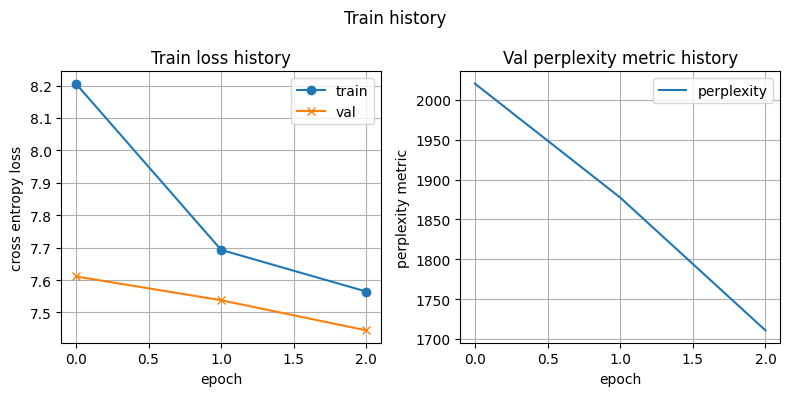

In [283]:
import numpy as np
import random
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt

# random
SEED = 43
torch.random.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# device - CPU or GPU
if torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'    

# модель 
model_params_real = {
    'vocab_size': vocab_df.size,
    'emded_dim': 128,
    'hidden_dim': 256,
    'n_layers': 2, 
    'dropout': 0.2, # 0.5
    'model_type': 'lstm'
}
model_params_debug = {
    'vocab_size': vocab_df.size,
    'emded_dim': 32,
    'hidden_dim': 64,
    'n_layers': 1,
    'dropout': 0,
    'model_type': 'lstm'
}
model_params = model_params_real
#model_params = model_params_debug

model = NNWikiTextComplete(**model_params)
model = model.to(device)
print(model)

# loss function
criterion = nn.CrossEntropyLoss()

# optimizer
learning_rate = 0.001
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# загрузчик данных
batch_size = 64 # 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, collate_fn=collate_fn, shuffle=True) 
val_loader = DataLoader(val_dataset, batch_size=batch_size, collate_fn=collate_fn) 

# цикл обучения
n_epochs = 3
max_iter = 500
max_iter_val = 500

train_loss_history = []
val_loss_history = []
val_ppl_history = []

for epoch in range(n_epochs):
    train_loss_avg = train_model(model, train_loader, optim, criterion, max_iter)
    train_loss_history.append(train_loss_avg)
    
    val_loss_avg, val_ppl = evaluate_model(model, val_loader, criterion, max_iter_val)
    val_loss_history.append(val_loss_avg)
    val_ppl_history.append(val_ppl)

    print(f'epoch:{epoch} - train_loss_avg = {train_loss_avg}, val_loss_avg = {val_loss_avg}, val_ppl = {val_ppl}')

print(f'result - \n\t loss_history = {train_loss_history}, \n\t val_loss_history = {val_loss_history}, \n\t  ppl_history = {val_ppl_history}')
plot_train_history(train_loss_history, val_loss_history, val_ppl_history)

In [296]:
# посчитает сколько обучаемых параметров у модели
total_params = sum(p.numel() for p in model.parameters())
print(f"total parameters: {total_params:,}")

total parameters: 12,229,435


In [284]:
# Сохраним модель после обучения
import pathlib as path
store_path = path.Path('data/models')
store_path.mkdir(exist_ok=True)
model.save_model(store_path / 'model-lstm.pth')

Model saved to data\models\model-lstm.pth


In [295]:
# Восстановим обученную модель 
import pathlib as path
store_path = path.Path('data/models')
model = NNWikiTextComplete.load_model(store_path / 'model-lstm.pth')
model

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = lstm
Model loaded from data\models\model-lstm.pth


NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)

### Визуальное тестирование обученной модели
- отобразим предсказание модели на тестовой выборке с выводом топ-10 слов кандидатов

In [286]:
# test датасет - токенизация налету, т.к. размер меньше
wiki_ds = pd.read_csv(preprocessing_path / 'dataset_clean.csv')
test_texts = wiki_ds[wiki_ds['stage'] == 'test']['texts'].tolist()

test_dataset = WikiTextTorchDataset(test_texts, tokenizer)

WikiTextTorchDataset __init()__: texts size = 2891, seq_len = 32, overlap = 16


100%|██████████| 2891/2891 [00:34<00:00, 83.23it/s] 

self.X len = 12206
self.y len = 12206


In [280]:
def show_test_samples_prediction(model: nn.Module, sample_data: dict):
    """
    Демонстрация работы модели по предсказанию следующего слова в тестовом датасете

    Args
        model - обученная модель
        sample_data - пачка данных (батч) из DataLoader
    """

    sample_tokens = sample_data['input_tokens']
    sample_lengths = sample_data['input_lengths']
    sample_true_tokens = sample_data['targets']

    logits = model(sample_tokens, sample_lengths)
    probs = torch.softmax(logits, dim=1) 

    # top 10 preditioctions
    top_probs, top_idxs = torch.topk(probs, k=10, dim=1)

    for i in range(test_text_size):

        top_token = top_idxs[i,0].item()
        top_proba = top_probs[i,0].item()
        pred_top_10_probas = top_probs[i]

        # convert to text
        text = tokenizer.conver_to_words(sample_tokens[i].tolist())
        pred_word = tokenizer.conver_to_words([top_token]).item()
        pred_top_10 = tokenizer.conver_to_words(top_idxs[i].tolist())
        true_words = tokenizer.conver_to_words(sample_true_tokens[i].tolist())

        print(f'{i+1} - text: "{" ".join(text)}"')
        print(f'    true word = "{true_words}"')
        print(f'    pred_word = "{pred_word}" (proba = {top_proba:.2%})')
        print(f'    pred_word_top_10        = {[f"{str(w):<8}" for w in pred_top_10]}')
        print(f'    pred_word_top_10 probas = {[f"{p.item():<8.2%}" for p in pred_top_10_probas]}')

In [287]:
init_random()

test_text_size = 5
test_loader = DataLoader(test_dataset, batch_size=test_text_size, collate_fn=collate_fn, shuffle=True) 
sample_text = next(iter(test_loader))

show_test_samples_prediction(model, sample_text)

# на момент отладки вывод:
# - так как модель практически не обучалась - всего 3 эпохи по 100 итераций из 1617 - то модель смогла выучить лишь самые популярные 10 слов, которые везде применяет

1 - text: "they each have detailed histories they are only verbal <UNK> that do not separate them from one another finally <UNK> noted that because almost all the points of hitler s speech"
    true word = "are"
    pred_word = "the" (proba = 6.24%)
    pred_word_top_10        = ['the     ', 'of      ', 'and     ', 'to      ', 'in      ', '<UNK>   ', 'a       ', 'as      ', 'on      ', 'was     ']
    pred_word_top_10 probas = ['6.24%   ', '4.87%   ', '3.48%   ', '3.22%   ', '2.98%   ', '2.50%   ', '1.54%   ', '1.24%   ', '1.14%   ', '1.13%   ']
2 - text: "but eddie insists the game will end only when <UNK> says it is over <UNK> agrees to continue after bert labels eddie a loser after 25 hours and an entire bottle"
    true word = "of"
    pred_word = "the" (proba = 5.51%)
    pred_word_top_10        = ['the     ', 'of      ', 'and     ', '<UNK>   ', 'to      ', 'in      ', 'a       ', 'as      ', 'was     ', 'on      ']
    pred_word_top_10 probas = ['5.51%   ', '2.72%   ', '2.46%   '

## Этап 3. Эксперимент: GRU vs LSTM
1. Заменить LSTM на GRU в модели.
2. Обучить GRU-модель с теми же гиперпараметрами.
3. Сравнить perplexity, количество параметров, время на эпоху.

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = gru
NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): GRU(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)


train epoch - batch size = 64:  31%|███       | 499/1617 [02:16<05:06,  3.65it/s]

epoch:0-iter:500 - loss = 8.301827430725098


epoch:0 - train_loss_avg = 8.215345910072326, val_loss_avg = 7.684279893426334, val_ppl = 2173.9039672911217


train epoch - batch size = 64:  31%|███       | 499/1617 [02:15<05:03,  3.68it/s]

epoch:1-iter:500 - loss = 8.13332748413086


epoch:1 - train_loss_avg = 7.777465686798096, val_loss_avg = 7.6297778999104215, val_ppl = 2058.592755424605


train epoch - batch size = 64:  31%|███       | 499/1617 [02:29<05:34,  3.35it/s]

epoch:2-iter:500 - loss = 7.442197799682617


epoch:2 - train_loss_avg = 7.685776077270508, val_loss_avg = 7.6131380109226, val_ppl = 2024.621423940494
result - 
	 loss_history = [8.215345910072326, 7.777465686798096, 7.685776077270508], 
	 val_loss_history = [7.684279893426334, 7.6297778999104215, 7.6131380109226], 
	  ppl_history = [np.float64(2173.9039672911217), np.float64(2058.592755424605), np.float64(2024.621423940494)]


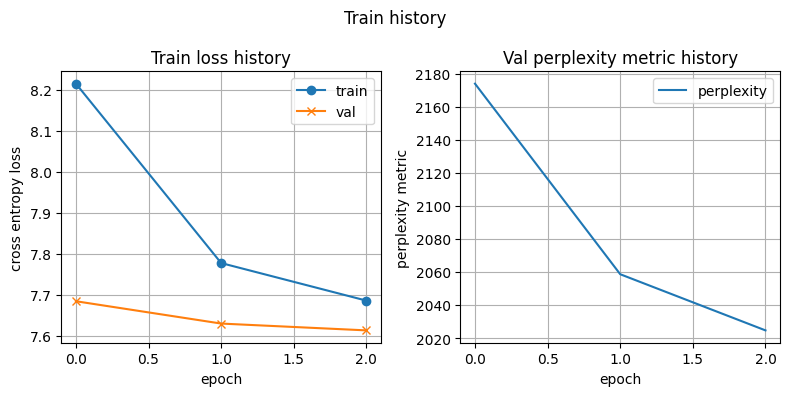

In [289]:
import numpy as np
import random
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt

# random
init_random()

# device - CPU or GPU
if torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'    

# модель 
model_params_real = {
    'vocab_size': vocab_df.size,
    'emded_dim': 128,
    'hidden_dim': 256,
    'n_layers': 2, 
    'dropout': 0.2, # 0.5
    'model_type': 'gru'
}
model_params_debug = {
    'vocab_size': vocab_df.size,
    'emded_dim': 32,
    'hidden_dim': 64,
    'n_layers': 1,
    'dropout': 0,
    'model_type': 'gru'
}
model_params = model_params_real
#model_params = model_params_debug

model = NNWikiTextComplete(**model_params)
model = model.to(device)
print(model)

# loss function
criterion = nn.CrossEntropyLoss()

# optimizer
learning_rate = 0.001
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# загрузчик данных
batch_size = 64 # 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, collate_fn=collate_fn, shuffle=True) 
val_loader = DataLoader(val_dataset, batch_size=batch_size, collate_fn=collate_fn) 

# цикл обучения
n_epochs = 3
max_iter = 500
max_iter_val = 500

train_loss_history = []
val_loss_history = []
val_ppl_history = []

for epoch in range(n_epochs):
    train_loss_avg = train_model(model, train_loader, optim, criterion, max_iter)
    train_loss_history.append(train_loss_avg)
    
    val_loss_avg, val_ppl = evaluate_model(model, val_loader, criterion, max_iter_val)
    val_loss_history.append(val_loss_avg)
    val_ppl_history.append(val_ppl)

    print(f'epoch:{epoch} - train_loss_avg = {train_loss_avg}, val_loss_avg = {val_loss_avg}, val_ppl = {val_ppl}')

print(f'result - \n\t loss_history = {train_loss_history}, \n\t val_loss_history = {val_loss_history}, \n\t  ppl_history = {val_ppl_history}')
plot_train_history(train_loss_history, val_loss_history, val_ppl_history)

In [294]:
# посчитает сколько обучаемых параметров у модели
total_params = sum(p.numel() for p in model.parameters())
print(f"total parameters: {total_params:,}")

total parameters: 11,999,035


In [290]:
# Сохраним модель после обучения

import pathlib as path
store_path = path.Path('data/models')
store_path.mkdir(exist_ok=True)

model.save_model(store_path / 'model-gru.pth')

Model saved to data\models\model-gru.pth


In [293]:
# Восстановим обученную модель 
import pathlib as path
store_path = path.Path('data/models')

model = NNWikiTextComplete.load_model(store_path / 'model-gru.pth')
model

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = gru
Model loaded from data\models\model-gru.pth


NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): GRU(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)

### Визуальное тестирование

In [292]:
init_random()

test_text_size = 5
test_loader = DataLoader(test_dataset, batch_size=test_text_size, collate_fn=collate_fn, shuffle=True) 
sample_text = next(iter(test_loader))

show_test_samples_prediction(model, sample_text)

# на момент отладки вывод:
# - так как модель практически не обучалась - всего 3 эпохи по 100 итераций из 1617 - то модель смогла выучить лишь самые популярные 10 слов, которые везде применяет

1 - text: "they each have detailed histories they are only verbal <UNK> that do not separate them from one another finally <UNK> noted that because almost all the points of hitler s speech"
    true word = "are"
    pred_word = "the" (proba = 6.36%)
    pred_word_top_10        = ['the     ', '<UNK>   ', 'of      ', 'and     ', 'a       ', 'to      ', 'in      ', 'was     ', 'for     ', 's       ']
    pred_word_top_10 probas = ['6.36%   ', '3.52%   ', '2.77%   ', '2.54%   ', '1.96%   ', '1.80%   ', '1.71%   ', '0.79%   ', '0.71%   ', '0.64%   ']
2 - text: "but eddie insists the game will end only when <UNK> says it is over <UNK> agrees to continue after bert labels eddie a loser after 25 hours and an entire bottle"
    true word = "of"
    pred_word = "the" (proba = 6.90%)
    pred_word_top_10        = ['the     ', '<UNK>   ', 'of      ', 'and     ', 'a       ', 'to      ', 'in      ', 'was     ', 'for     ', 's       ']
    pred_word_top_10 probas = ['6.90%   ', '3.72%   ', '2.98%   '

# Сравнение

Сравнение показателей обучения моделей LSTM vs GRU

| Тип модели | Размер батча | N эпох | N итераций обучения| N итерация валидации | Время работы | Val loss | Perplexity | N параметров 
| --         | --           | --     | --                 | --                   | --           | --       | --         | --
| LSTM       | 64           | 3      | 100                | 100                  | 9 м 57.8 сек | 7.44     | 1710.62    | 12,229,435
| GRU        | 64           | 3      | 100                | 100                  | 7 м 29.4 сек | 7.61     | 2024.62    | 11,999,035

Вывод:
- время обучения 
    - LSTM требует примерно на 30% больше времени, чем GRU
- ошибка (loss) 
    - LSTM достиг меньшей ошибки, снизившись с 7.61 до 7.44 за 3 эпохи
    - GRU - c 7.68 до 7.61
- метрика perplexity
    - LSTM достиг меньше "сомневается в результате", чем GRU - 1710 vs 2024

Таким образом LSTM побеждает в качестве, но требует больше времени/ресурсов на обучение.

--
P.S. По визуальному сравнению реального предсказанию модели пока могут только предсказывать простые предлоги/союзы